# 🎯 Task: CIFAR-30 Classification with Pretrained Models

**Your Mission**: Implement and compare different training approaches for CIFAR-30 classification!

---

## 📋 Learning Objectives

By completing this task, you will:

1. **🏗️ Implement Model Architectures**: Create models using torchvision or timm
2. **🔄 Apply Transfer Learning**: Implement three different training strategies
3. **⚖️ Compare Performance**: Analyze the trade-offs between approaches
4. **📊 Evaluate Results**: Measure accuracy, speed, and efficiency

---

## 🎯 Task Overview

You will implement **three different approaches** to train a CNN on CIFAR-30:

### **Approach 1: 🎲 Training from Scratch**
- Use a CNN architecture with random initialization
- Train the entire model from scratch
- Compare performance with pretrained approaches

### **Approach 2: ❄️ Feature Extraction**
- Use a pretrained model (freeze backbone)
- Only train the classifier head
- Fastest training approach

### **Approach 3: 🔥 Fine-tuning**
- Use a pretrained model
- Fine-tune the entire network
- Usually best performance

### **CIFAR-30 Dataset:**
- **Classes**: 30 (first 30 classes from CIFAR-100)
- **Images**: 60,000 (50,000 train + 10,000 test)
- **Size**: 32×32×3 (RGB)
- **Challenge**: More complex than CIFAR-10

---

## 📚 Available Tools

You can use either:
- **torchvision.models**: ResNet, VGG, DenseNet, EfficientNet, etc.
- **timm**: Hundreds of pretrained models (Vision Transformers, ConvNeXt, etc.)

**Recommended models**: ResNet18/34, EfficientNet-B0, ConvNeXt-Tiny, or ViT-Small

---

## 📦 Setup & Data Preparation (Boilerplate)

**This section is provided for you - focus on the implementation tasks below!**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np
import time
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# Uncomment if you want to use timm (install with: pip install timm)
# import timm

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print("📦 Libraries imported successfully!")

🔧 Using device: cpu
📦 Libraries imported successfully!


In [ ]:
# CIFAR-30 class names (first 30 from CIFAR-100)
cifar30_classes = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle',
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel',
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock',
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur'
]

NUM_CLASSES = 30

print(f"🏷️ CIFAR-30 Classes ({NUM_CLASSES} total):")
for i, class_name in enumerate(cifar30_classes):
    print(f"  {i:2d}: {class_name}")

🏷️ CIFAR-30 Classes (30 total):
   0: apple
   1: aquarium_fish
   2: baby
   3: bear
   4: beaver
   5: bed
   6: bee
   7: beetle
   8: bicycle
   9: bottle
  10: bowl
  11: boy
  12: bridge
  13: bus
  14: butterfly
  15: camel
  16: can
  17: castle
  18: caterpillar
  19: cattle
  20: chair
  21: chimpanzee
  22: clock
  23: cloud
  24: cockroach
  25: couch
  26: crab
  27: crocodile
  28: cup
  29: dinosaur


In [ ]:
# Data transformations (provided)
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],  # ImageNet normalization
                        std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

def create_cifar30_subset(dataset):
    """Create a subset of CIFAR-100 with only the first 30 classes."""
    indices = [i for i, (_, label) in enumerate(dataset) if label < NUM_CLASSES]
    return Subset(dataset, indices)

# Load datasets
full_trainset = torchvision.datasets.CIFAR100(root='./data', train=True,
                                             download=True, transform=transform_train)
full_testset = torchvision.datasets.CIFAR100(root='./data', train=False,
                                            download=False, transform=transform_test)

# Create CIFAR-30 subsets
trainset = create_cifar30_subset(full_trainset)
testset = create_cifar30_subset(full_testset)

# Create dataloaders
train_loader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)

print(f"📊 CIFAR-30 Dataset loaded!")
print(f"  • Training samples: {len(trainset):,}")
print(f"  • Test samples: {len(testset):,}")
print(f"  • Batch size: {train_loader.batch_size}")
print(f"  • Number of classes: {NUM_CLASSES}")

100%|██████████| 169M/169M [00:03<00:00, 43.5MB/s]


📊 CIFAR-30 Dataset loaded!
  • Training samples: 15,000
  • Test samples: 3,000
  • Batch size: 128
  • Number of classes: 30


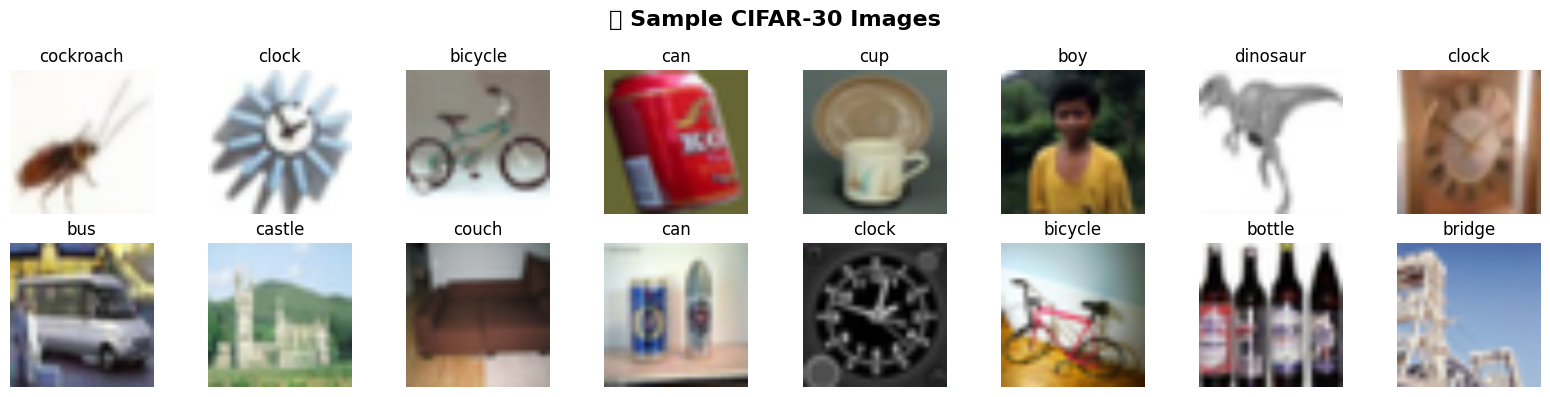

In [5]:
# Visualize sample images (provided)
def show_sample_images():
    """Display sample images from CIFAR-30 dataset."""
    transform_vis = transforms.Compose([transforms.Resize(224), transforms.ToTensor()])
    full_dataset = torchvision.datasets.CIFAR100(root='./data', train=True, transform=transform_vis)
    vis_dataset = create_cifar30_subset(full_dataset)
    vis_loader = DataLoader(vis_dataset, batch_size=16, shuffle=True)

    images, labels = next(iter(vis_loader))

    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    fig.suptitle('🖼️ Sample CIFAR-30 Images', fontsize=16, fontweight='bold')

    for i in range(16):
        row, col = i // 8, i % 8
        img = images[i].permute(1, 2, 0).numpy()
        axes[row, col].imshow(img)
        axes[row, col].set_title(f'{cifar30_classes[labels[i]]}')
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

show_sample_images()

## 🚀 TASK 1: Implement Model Creation Functions

**Your job**: Create a function that returns models for different training approaches.

### 📝 Requirements:

1. **Function signature**: `create_model(approach: str, model_name: str = 'resnet18') -> nn.Module`
2. **Approaches to support**:
   - `'scratch'`: Random initialization
   - `'feature_extraction'`: Pretrained backbone (frozen) + new classifier
   - `'fine_tuning'`: Pretrained backbone + trainable classifier

3. **Model options** (choose one or implement multiple):
   - `torchvision.models`: ResNet18, ResNet34, EfficientNet, etc.
   - `timm`: Any model from timm library

### 💡 Hints:
- For feature extraction: freeze backbone with `param.requires_grad = False`
- Replace final classifier to output 30 classes
- For timm models: use `timm.create_model(model_name, pretrained=True, num_classes=30)`

### 🎯 Expected Output:
- Print total parameters, trainable parameters, and frozen parameters
- Return model moved to the correct device

In [ ]:
def create_model(approach: str, model_name: str = 'resnet18') -> nn.Module:
    """Create model with different training approaches.

    Args:
        approach (str): 'scratch', 'feature_extraction', or 'fine_tuning'
        model_name (str): Name of the model architecture

    Returns:
        nn.Module: Model ready for training

    Raises:
        ValueError: If approach is not supported
    """
    # TODO: Implement your model creation logic here
    #
    # Suggested structure:
    # 1. Create model based on approach (scratch vs pretrained)
    # 2. Modify classifier for 30 classes
    # 3. Handle parameter freezing for feature extraction
    # 4. Print parameter statistics
    # 5. Move to device and return

    pass  # Replace with your implementation

# Test your function
print("Testing model creation:")
test_model = create_model('scratch')
print(f"Model created successfully!")

## 🏃‍♂️ TASK 2: Implement Training Functions

**Your job**: Implement training and validation functions.

### 📝 Requirements:

1. **`train_epoch(model, train_loader, optimizer, criterion, device)`**:
   - Train model for one epoch
   - Return training loss and accuracy

2. **`validate_epoch(model, test_loader, criterion, device)`**:
   - Evaluate model on test set
   - Return validation loss and accuracy

### 💡 Hints:
- Use `model.train()` and `model.eval()` appropriately
- Use `torch.no_grad()` for validation
- Calculate accuracy as percentage of correct predictions

In [ ]:
def train_epoch(model, train_loader, optimizer, criterion, device):
    """Train model for one epoch.

    Args:
        model (nn.Module): Model to train
        train_loader (DataLoader): Training data loader
        optimizer (torch.optim.Optimizer): Optimizer
        criterion (nn.Module): Loss function
        device (torch.device): Device to use

    Returns:
        tuple: (average_loss, accuracy_percentage)
    """
    # TODO: Implement training epoch
    #
    # Suggested structure:
    # 1. Set model to training mode
    # 2. Loop through batches
    # 3. Forward pass, compute loss, backward pass
    # 4. Track running loss and correct predictions
    # 5. Return average loss and accuracy

    pass  # Replace with your implementation


def validate_epoch(model, test_loader, criterion, device):
    """Validate model for one epoch.

    Args:
        model (nn.Module): Model to validate
        test_loader (DataLoader): Test data loader
        criterion (nn.Module): Loss function
        device (torch.device): Device to use

    Returns:
        tuple: (average_loss, accuracy_percentage)
    """
    # TODO: Implement validation epoch
    #
    # Suggested structure:
    # 1. Set model to evaluation mode
    # 2. Disable gradients with torch.no_grad()
    # 3. Loop through batches
    # 4. Forward pass, compute loss
    # 5. Track running loss and correct predictions
    # 6. Return average loss and accuracy

    pass  # Replace with your implementation

print("Training functions defined!")

## ⚙️ TASK 3: Implement Training Pipeline

**Your job**: Create a complete training pipeline function.

### 📝 Requirements:

1. **Function signature**: `train_model(approach: str, model_name: str = 'resnet18', epochs: int = 10) -> tuple`
2. **Pipeline steps**:
   - Create model using your `create_model` function
   - Set up optimizer and loss function
   - Train for specified epochs
   - Track training history (loss, accuracy, time)
   - Return trained model and history

### 💡 Optimizer Suggestions:
- **From scratch**: SGD with lr=0.01, momentum=0.9
- **Feature extraction**: SGD with lr=0.01
- **Fine-tuning**: Different learning rates for backbone (0.001) and classifier (0.01)

### 🎯 Expected Output:
- Print progress for each epoch
- Return model and training history dictionary

In [ ]:
def train_model(approach: str, model_name: str = 'resnet18', epochs: int = 10):
    """Complete training pipeline for one approach.

    Args:
        approach (str): Training approach ('scratch', 'feature_extraction', 'fine_tuning')
        model_name (str): Model architecture name
        epochs (int): Number of training epochs

    Returns:
        tuple: (trained_model, history_dict)
    """
    print(f"\n{'='*60}")
    print(f"🚀 Training: {approach.upper().replace('_', ' ')} - {model_name}")
    print(f"{'='*60}")

    # TODO: Implement complete training pipeline
    #
    # Suggested structure:
    # 1. Create model
    # 2. Set up optimizer and criterion
    # 3. Initialize history tracking
    # 4. Training loop for each epoch:
    #    - Train epoch
    #    - Validate epoch
    #    - Update history
    #    - Print progress
    # 5. Print final results
    # 6. Return model and history

    pass  # Replace with your implementation

print("Training pipeline function defined!")

## 🧪 TASK 4: Run Experiments

**Your job**: Train models using all three approaches and compare results.

### 📝 Requirements:

1. Train three models with your chosen architecture:
   - **Feature Extraction** (fastest - run this first)
   - **Fine-tuning** (best performance)
   - **From Scratch** (baseline)

2. For each approach:
   - Use 10-15 epochs
   - Measure training time
   - Track accuracy progression

### 💡 Experiment Tips:
- Start with feature extraction (fastest to debug)
- If using limited compute, reduce epochs or batch size
- Save models if you want to avoid retraining

In [ ]:
# TODO: Run your experiments here
#
# Example structure:
# model1, history1 = train_model('feature_extraction', epochs=10)
# model2, history2 = train_model('fine_tuning', epochs=10)
# model3, history3 = train_model('scratch', epochs=10)

# Experiment 1: Feature Extraction
print("Starting Feature Extraction experiment...")
# Your code here

# Experiment 2: Fine-tuning
print("Starting Fine-tuning experiment...")
# Your code here

# Experiment 3: From Scratch
print("Starting From Scratch experiment...")
# Your code here

## 📊 TASK 5: Analyze and Compare Results

**Your job**: Create visualizations and analysis of your experimental results.

### 📝 Requirements:

1. **Create comparison plots**:
   - Training accuracy curves
   - Validation accuracy curves
   - Training time comparison

2. **Calculate metrics**:
   - Best validation accuracy for each approach
   - Time to convergence
   - Average time per epoch

3. **Analysis questions** (answer in markdown):
   - Which approach achieved the best accuracy?
   - Which approach was fastest?
   - What's the speed vs accuracy trade-off?
   - When would you use each approach?

In [ ]:
def plot_comparison_results(histories: dict):
    """Plot comparison of different training approaches.

    Args:
        histories (dict): Dictionary with approach names as keys and history dicts as values
    """
    # TODO: Implement visualization function
    #
    # Suggested plots:
    # 1. Training accuracy over epochs
    # 2. Validation accuracy over epochs
    # 3. Training loss over epochs
    # 4. Time per epoch comparison (bar plot)

    pass  # Replace with your implementation

def analyze_results(histories: dict):
    """Print detailed analysis of experimental results.

    Args:
        histories (dict): Dictionary with approach names as keys and history dicts as values
    """
    # TODO: Implement analysis function
    #
    # Suggested analysis:
    # 1. Best accuracy achieved by each approach
    # 2. Time to reach certain accuracy thresholds
    # 3. Total training time comparison
    # 4. Speed vs accuracy trade-offs

    pass  # Replace with your implementation

# TODO: Use your functions to analyze results
# Example:
# all_histories = {
#     'feature_extraction': history1,
#     'fine_tuning': history2,
#     'scratch': history3
# }
# plot_comparison_results(all_histories)
# analyze_results(all_histories)

## 📝 TASK 6: Reflection and Analysis

**Your job**: Answer the following questions based on your experimental results.

### 🤔 Analysis Questions:

1. **Performance Comparison**:
   - Which approach achieved the highest validation accuracy?
   - How much better was the best approach compared to training from scratch?

2. **Speed Analysis**:
   - Which approach was fastest to train?
   - How much faster was feature extraction compared to training from scratch?

3. **Practical Considerations**:
   - When would you use feature extraction?
   - When would you use fine-tuning?
   - When might training from scratch be necessary?

4. **Transfer Learning Benefits**:
   - Why do pretrained models perform better on CIFAR-30?
   - What features might the pretrained models have learned?

### 💭 Your Analysis:

**Write your analysis here:**

<!-- TODO: Replace this with your detailed analysis -->

---

## 🎯 BONUS TASKS (Optional)

If you want to explore further:

### 🌟 Bonus Task 1: Different Architectures
- Try different models (EfficientNet, Vision Transformer, ConvNeXt)
- Compare how architecture choice affects the pretrained vs scratch gap

### 🌟 Bonus Task 2: Learning Rate Scheduling
- Implement learning rate scheduling (StepLR, CosineAnnealingLR)
- Compare how it affects different approaches

### 🌟 Bonus Task 3: Data Augmentation
- Add more aggressive data augmentation
- See how it affects the performance gap between approaches

### 🌟 Bonus Task 4: Gradual Unfreezing
- Implement gradual unfreezing for fine-tuning
- Start with frozen backbone, gradually unfreeze layers

---

## 🎉 Congratulations!

You've successfully implemented and compared different transfer learning approaches!

### 🔑 Key Takeaways:
- **Transfer learning is powerful** for complex classification tasks
- **Different approaches** offer different speed vs accuracy trade-offs
- **Pretrained models** provide a huge advantage over training from scratch
- **Architecture choice** matters for transfer learning effectiveness

These skills will be invaluable for real-world computer vision projects! 🚀